In [2]:
%load_ext autoreload
%autoreload 2

# TASK 1 - Data Understanding

## Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from transformations import center_and_scale, drop_boolean

First we load both datasets.

In [2]:

df_cyclists = pd.read_csv('../dataset/cyclists.csv', skipinitialspace=True)
df_races = pd.read_csv('../dataset/races.csv', skipinitialspace=True)

In [3]:
df_races['date'] = pd.to_datetime(df_races['date'])

df_races['time'] = df_races['date'].dt.time
df_races['date'] = df_races['date'].dt.date

In [4]:
display(df_cyclists.head())
display(df_races.head())

,_url,name,birth_year,weight,height,nationality
0,bruno-surra,Bruno Surra,1964.0,NaN,NaN,Italy
1,gerard-rue,Gérard Rué,1965.0,74.0,182.0,France
2,jan-maas,Jan Maas,1996.0,69.0,189.0,Netherlands
3,nathan-van-hooydonck,Nathan Van Hooydonck,1995.0,78.0,192.0,Belgium
4,jose-felix-parra,José Félix Parra,1997.0,55.0,171.0,Spain


,_url,name,points,uci_points,length,climb_total,profile,startlist_quality,average_temperature,date,position,cyclist,cyclist_age,is_tarmac,is_cobbled,is_gravel,cyclist_team,delta,time
0,tour-de-france/1978/stage-6,Tour de France,100.0,NaN,162000.0,1101.0,1.0,1241,NaN,1978-07-05,0,sean-kelly,22.0,True,False,False,vini-ricordi-pinarello-sidermec-1986,0.0,04:02:24
1,tour-de-france/1978/stage-6,Tour de France,100.0,NaN,162000.0,1101.0,1.0,1241,NaN,1978-07-05,1,gerrie-knetemann,27.0,True,False,False,norway-1987,0.0,04:02:24
2,tour-de-france/1978/stage-6,Tour de France,100.0,NaN,162000.0,1101.0,1.0,1241,NaN,1978-07-05,2,rene-bittinger,24.0,True,False,False,NaN,0.0,04:02:24
3,tour-de-france/1978/stage-6,Tour de France,100.0,NaN,162000.0,1101.0,1.0,1241,NaN,1978-07-05,3,joseph-bruyere,30.0,True,False,False,navigare-blue-storm-1993,0.0,04:02:24
4,tour-de-france/1978/stage-6,Tour de France,100.0,NaN,162000.0,1101.0,1.0,1241,NaN,1978-07-05,4,sven-ake-nilsson,27.0,True,False,False,spain-1991,0.0,04:02:24


Mean for each tour and startlist_quality

Show the number of rows and columns in the two datasets

In [7]:
print('cyclists instances shape: ', df_cyclists.shape)
print('races instances shape: ', df_races.shape)
print('unique races number: ', len(df_races['_url'].unique()))
print('mean of the teams for each race: ', round(df_races.shape[0]/len(df_races['_url'].unique())))

cyclists instances shape:  (6134, 6)
races instances shape:  (589865, 19)
unique races number:  5281
mean of the teams for each race:  112


Check the null values number and field types per field. From this analysis, there are not syntatic values error otherwise the dtype is object for number values.

In [8]:
display(df_cyclists.info())
display(df_races.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6134 entries, 0 to 6133
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   _url         6134 non-null   object 
 1   name         6134 non-null   object 
 2   birth_year   6121 non-null   float64
 3   weight       3078 non-null   float64
 4   height       3143 non-null   float64
 5   nationality  6133 non-null   object 
dtypes: float64(3), object(3)
memory usage: 287.7+ KB


None

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 589865 entries, 0 to 589864
Data columns (total 19 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   _url                 589865 non-null  object 
 1   name                 589865 non-null  object 
 2   points               589388 non-null  float64
 3   uci_points           251086 non-null  float64
 4   length               589865 non-null  float64
 5   climb_total          442820 non-null  float64
 6   profile              441671 non-null  float64
 7   startlist_quality    589865 non-null  int64  
 8   average_temperature  29933 non-null   float64
 9   date                 589865 non-null  object 
 10  position             589865 non-null  int64  
 11  cyclist              589865 non-null  object 
 12  cyclist_age          589752 non-null  float64
 13  is_tarmac            589865 non-null  bool   
 14  is_cobbled           589865 non-null  bool   
 15  is_gravel        

None

Here's a breakdown of the columns included in the output:
- Numeric Columns: count, mean, std, min, 25%, 50%, 75%, max.

- Categorical (Object) Columns: count, unique, top, freq.

- Datetime Columns: count, unique, top, freq, first, last.

- Boolean Columns: count, unique, top, and freq.

In [9]:
display(df_cyclists.describe(include='all'))
display(df_races.describe(include='all'))

,_url,name,birth_year,weight,height,nationality
count,6134,6134,6121.000000,3078.000000,3143.000000,6133
unique,6134,6127,NaN,NaN,NaN,72
top,bruno-surra,Jesús López,NaN,NaN,NaN,Italy
freq,1,2,NaN,NaN,NaN,1029
mean,NaN,NaN,1974.071884,68.658739,179.815145,NaN
std,NaN,NaN,15.535834,6.348183,6.443447,NaN
min,NaN,NaN,1933.000000,48.000000,154.000000,NaN
25%,NaN,NaN,1962.000000,64.000000,175.000000,NaN
50%,NaN,NaN,1974.000000,69.000000,180.000000,NaN
75%,NaN,NaN,1987.000000,73.000000,184.000000,NaN


,_url,name,points,uci_points,length,climb_total,profile,startlist_quality,average_temperature,date,position,cyclist,cyclist_age,is_tarmac,is_cobbled,is_gravel,cyclist_team,delta,time
count,589865,589865,589388.000000,251086.000000,589865.000000,442820.000000,441671.000000,589865.000000,29933.000000,589865,589865.000000,589865,589752.000000,589865,589865,589865,430704,589865.000000,589865
unique,5281,61,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4708,NaN,6095,NaN,2,1,1,91,NaN,24444
top,tour-de-france/1986/stage-1,Tour de France,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1998-06-18,NaN,matteo-tosatto,NaN,True,False,False,liberty-seguros-wurth-team-2005,NaN,04:24:10
freq,210,145500,NaN,NaN,NaN,NaN,NaN,NaN,NaN,407,NaN,959,NaN,536042,589865,589865,8869,NaN,525
mean,NaN,NaN,89.221635,74.601547,166776.180584,2330.469215,2.611611,1101.161178,21.731768,NaN,74.219491,NaN,28.486208,NaN,NaN,NaN,NaN,418.292794,NaN
std,NaN,NaN,54.435330,100.947962,64545.605664,1375.710722,1.491741,380.586928,5.884761,NaN,48.404023,NaN,3.855631,NaN,NaN,NaN,NaN,842.961596,NaN
min,NaN,NaN,18.000000,6.000000,1000.000000,2.000000,1.000000,115.000000,10.000000,NaN,0.000000,NaN,13.000000,NaN,NaN,NaN,NaN,-6906.000000,NaN
25%,NaN,NaN,50.000000,16.000000,152500.000000,1309.000000,1.000000,844.000000,17.000000,NaN,32.000000,NaN,26.000000,NaN,NaN,NaN,NaN,10.000000,NaN
50%,NaN,NaN,80.000000,60.000000,178200.000000,2255.000000,2.000000,988.000000,22.000000,NaN,70.000000,NaN,28.000000,NaN,NaN,NaN,NaN,156.000000,NaN
75%,NaN,NaN,100.000000,100.000000,203500.000000,3273.000000,4.000000,1309.000000,26.000000,NaN,112.000000,NaN,31.000000,NaN,NaN,NaN,NaN,624.000000,NaN


In [10]:
display(df_cyclists.isnull().sum())
display(df_races.isnull().sum())

_url              0
name              0
birth_year       13
weight         3056
height         2991
nationality       1
dtype: int64

_url                        0
name                        0
points                    477
uci_points             338779
length                      0
climb_total            147045
profile                148194
startlist_quality           0
average_temperature    559932
date                        0
position                    0
cyclist                     0
cyclist_age               113
is_tarmac                   0
is_cobbled                  0
is_gravel                   0
cyclist_team           159161
delta                       0
time                        0
dtype: int64

Find duplicated rows

In [11]:
num_duplicates_cyclists = df_cyclists.duplicated()
num_duplicates_races = df_races.duplicated()

print(f'Number of duplicated rows in cyclists dataset: {num_duplicates_cyclists.sum()}')
print(f'Number of duplicated rows in races dataset: {num_duplicates_races.sum()}')

Number of duplicated rows in cyclists dataset: 0
Number of duplicated rows in races dataset: 0


Now we try to visualize the null values in both datasets.

<Axes: >

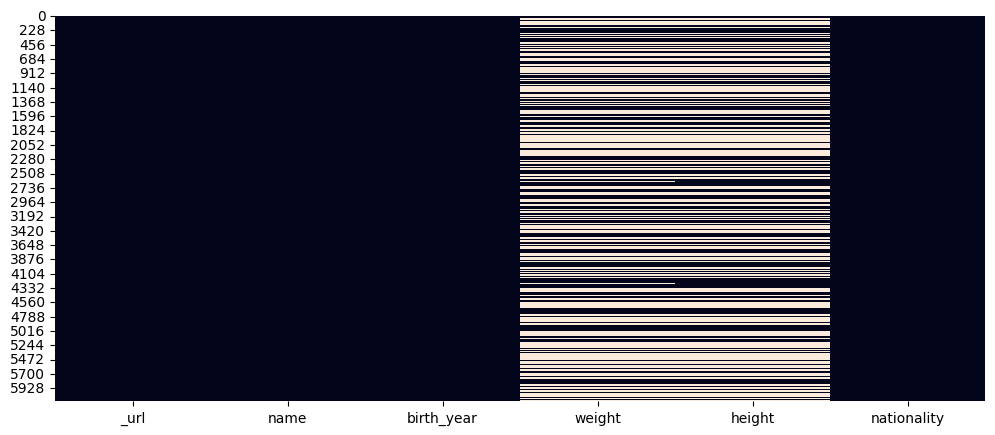

In [12]:
fig, ax = plt.subplots(figsize= (12, 5))
sns.heatmap(df_cyclists.isnull(), cbar=False, xticklabels=True, ax=ax)

<Axes: >

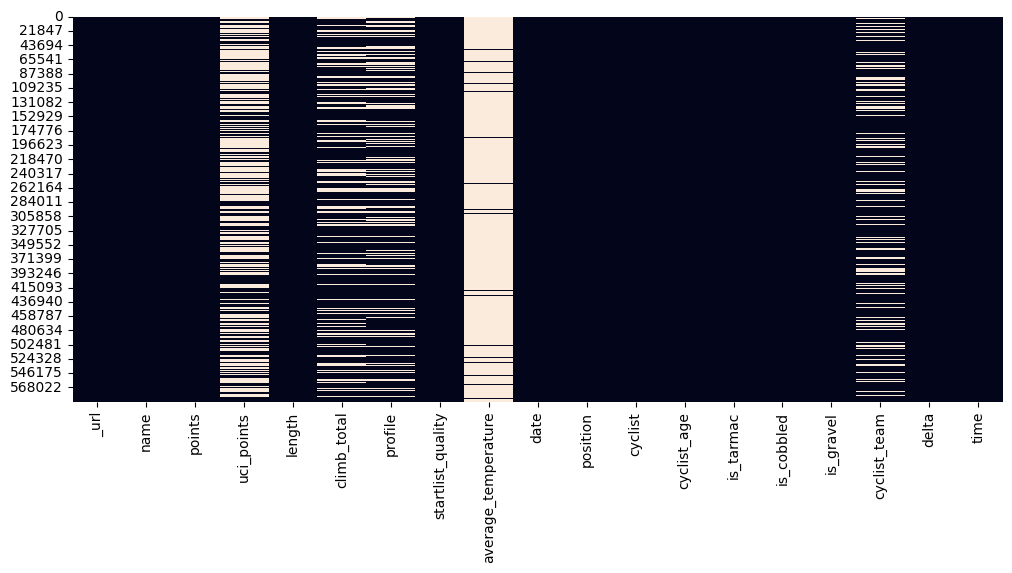

In [13]:
fig, ax = plt.subplots(figsize= (12, 5))
sns.heatmap(df_races.isnull(), cbar=False, xticklabels=True, ax=ax)

## Feature Informations

"Type" indicates the wanted feature Datatype for conversion, most of the columns are defaulted to object type and need casting.
- **`_url_`**
    - **Type**: string
    - **Description**: Identifier of the race
- **`name`**
    - **Type**: string
    - **Description**: The name of the race
- **`points`**
    - **Type**: Float64
    - **Description**: Points assigned to the race, higher points, higher prestige 
- **`uci_points`**
    - **Type**: Float64
    - **Description**: Alternative points assigned to the race
- **`lenght`**
    - **Type**: Float64
    - **Description**: Length of the race
- **`climb_total`**
    - **Type**: Float64
    - **Description**: Total meters climbed during the race
- **`profile`**
    - **Type**: Categorical
    - **Description**: Race profile of increasing difficulty: flat, hilly, mountainous, high mountains
- **`startlist_quality`**
    - **Type**: Float64
    - **Description**: How strong are the participants at the race?
- **`average_temperature`**
    - **Type**: Float64
    - **Description**: Average temperature during the race
- **`date`**
    - **Type**: datetime
    - **Description**: Race date. Starting time is irrelevant and noisy
- **`position`**
    - **Type**: Int64
    - **Description**: Points assigned to the race, higher points, higher prestige
- **`cyclist`**
    - **Type**: Float64
    - **Description**: Finish position of the given cyclist
- **`cyclist_age`**
    - **Type**: Int64
    - **Description**: Age of a given cyclist
- **`is_tarmac`**/**`is_cobbled`**/**`is_gravel`**
    - **Type**: bool
    - **Description**: Type of path surface given a race
- **`delta`**
    - **Type**: Float64
    - **Description**: How many seconds after the first-placed did the cyclist get to
the finish?
- **`weight`**
    - **Type**: Float64
    - **Description**: Weight of the cyclist
- **`height`**
    - **Type**: Float64
    - **Description**: Height of the cyclist
- **`nationality`**
    - **Type**: string
    - **Description**: Nationality of the cyclist

## Data Casting

Since in the dataset there some features mapped as object, we need to cast them in the proper data type.

In [14]:
# convert date in datetime type
df_races['date'] = pd.to_datetime(df_races['date'],  errors='coerce')

# convert object in string
df_races[['_url', 'name', 'cyclist', 'cyclist_team']] = df_races[['_url', 'name', 'cyclist', 'cyclist_team']].astype('string')
df_cyclists[['_url', 'name', 'nationality']] = df_cyclists[['_url', 'name', 'nationality']].astype('string')

# convert int in Int64
df_races[['startlist_quality', 'position']] = df_races[['startlist_quality', 'position']].astype('Int64')

# convert 'profile' in categorical
df_races[['profile']] = df_races[['profile']].astype('category')

display(df_cyclists.info())
display(df_races.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6134 entries, 0 to 6133
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   _url         6134 non-null   string 
 1   name         6134 non-null   string 
 2   birth_year   6121 non-null   float64
 3   weight       3078 non-null   float64
 4   height       3143 non-null   float64
 5   nationality  6133 non-null   string 
dtypes: float64(3), string(3)
memory usage: 287.7 KB


None

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 589865 entries, 0 to 589864
Data columns (total 19 columns):
 #   Column               Non-Null Count   Dtype         
---  ------               --------------   -----         
 0   _url                 589865 non-null  string        
 1   name                 589865 non-null  string        
 2   points               589388 non-null  float64       
 3   uci_points           251086 non-null  float64       
 4   length               589865 non-null  float64       
 5   climb_total          442820 non-null  float64       
 6   profile              441671 non-null  category      
 7   startlist_quality    589865 non-null  Int64         
 8   average_temperature  29933 non-null   float64       
 9   date                 589865 non-null  datetime64[ns]
 10  position             589865 non-null  Int64         
 11  cyclist              589865 non-null  string        
 12  cyclist_age          589752 non-null  float64       
 13  is_tarmac     

None

Lets see the distribution after casting

In [15]:
display(df_cyclists.describe(include='all'))
display(df_races.describe(include='all'))

,_url,name,birth_year,weight,height,nationality
count,6134,6134,6121.000000,3078.000000,3143.000000,6133
unique,6134,6127,NaN,NaN,NaN,72
top,bruno-surra,Jesús López,NaN,NaN,NaN,Italy
freq,1,2,NaN,NaN,NaN,1029
mean,NaN,NaN,1974.071884,68.658739,179.815145,NaN
std,NaN,NaN,15.535834,6.348183,6.443447,NaN
min,NaN,NaN,1933.000000,48.000000,154.000000,NaN
25%,NaN,NaN,1962.000000,64.000000,175.000000,NaN
50%,NaN,NaN,1974.000000,69.000000,180.000000,NaN
75%,NaN,NaN,1987.000000,73.000000,184.000000,NaN


,_url,name,points,uci_points,length,climb_total,profile,startlist_quality,average_temperature,date,position,cyclist,cyclist_age,is_tarmac,is_cobbled,is_gravel,cyclist_team,delta,time
count,589865,589865,589388.000000,251086.000000,589865.000000,442820.000000,441671.0,589865.0,29933.000000,589865,589865.0,589865,589752.000000,589865,589865,589865,430704,589865.000000,589865
unique,5281,61,NaN,NaN,NaN,NaN,5.0,<NA>,NaN,NaN,<NA>,6095,NaN,2,1,1,91,NaN,24444
top,tour-de-france/1986/stage-1,Tour de France,NaN,NaN,NaN,NaN,1.0,<NA>,NaN,NaN,<NA>,matteo-tosatto,NaN,True,False,False,liberty-seguros-wurth-team-2005,NaN,04:24:10
freq,210,145500,NaN,NaN,NaN,NaN,131344.0,<NA>,NaN,NaN,<NA>,959,NaN,536042,589865,589865,8869,NaN,525
mean,NaN,NaN,89.221635,74.601547,166776.180584,2330.469215,NaN,1101.161178,21.731768,2006-08-11 17:59:28.544666880,74.219491,NaN,28.486208,NaN,NaN,NaN,NaN,418.292794,NaN
min,NaN,NaN,18.000000,6.000000,1000.000000,2.000000,NaN,115.0,10.000000,1970-02-28 00:00:00,0.0,NaN,13.000000,NaN,NaN,NaN,NaN,-6906.000000,NaN
25%,NaN,NaN,50.000000,16.000000,152500.000000,1309.000000,NaN,844.0,17.000000,1999-07-18 00:00:00,32.0,NaN,26.000000,NaN,NaN,NaN,NaN,10.000000,NaN
50%,NaN,NaN,80.000000,60.000000,178200.000000,2255.000000,NaN,988.0,22.000000,2008-05-03 00:00:00,70.0,NaN,28.000000,NaN,NaN,NaN,NaN,156.000000,NaN
75%,NaN,NaN,100.000000,100.000000,203500.000000,3273.000000,NaN,1309.0,26.000000,2015-08-29 00:00:00,112.0,NaN,31.000000,NaN,NaN,NaN,NaN,624.000000,NaN
max,NaN,NaN,350.000000,800.000000,338000.000000,6974.000000,NaN,2047.0,36.000000,2023-07-29 00:00:00,209.0,NaN,56.000000,NaN,NaN,NaN,NaN,61547.000000,NaN


Since we have `_url` feature in both datasets, we can actually merge races and cyclists dataset.
Some merged features name has been changed.

In [5]:
df_merged = pd.merge(df_races, df_cyclists, left_on='cyclist', right_on='_url')

df_merged['id_race'] = df_merged['_url_x']
df_merged['name_race'] = df_merged['name_x']
df_merged['id_cyclist'] = df_merged['_url_y']
df_merged['name_cyclist'] = df_merged['name_y']

df_merged = df_merged.drop(["_url_x", "name_x", "_url_y", "name_y"], axis=1)

df_races['date'] = pd.to_datetime(df_races['date'])

df_races['time'] = df_races['date'].dt.time
df_races['date'] = df_races['date'].dt.date

display(df_merged.head())
display(df_merged.info())

,points,uci_points,length,climb_total,profile,startlist_quality,average_temperature,date,position,cyclist,...,delta,time,birth_year,weight,height,nationality,id_race,name_race,id_cyclist,name_cyclist
0,100.0,NaN,162000.0,1101.0,1.0,1241,NaN,1978-07-05,0,sean-kelly,...,0.0,04:02:24,1956.0,77.0,180.0,Ireland,tour-de-france/1978/stage-6,Tour de France,sean-kelly,Sean Kelly
1,100.0,NaN,52000.0,1351.0,5.0,1241,NaN,1978-07-14,62,sean-kelly,...,702.0,01:37:33,1956.0,77.0,180.0,Ireland,tour-de-france/1978/stage-14,Tour de France,sean-kelly,Sean Kelly
2,275.0,NaN,265000.0,NaN,NaN,602,NaN,1980-03-30,14,sean-kelly,...,165.0,06:39:30,1956.0,77.0,180.0,Ireland,ronde-van-vlaanderen/1980/result,Ronde van Vlaanderen / Tour des Flandres,sean-kelly,Sean Kelly
3,80.0,NaN,84000.0,NaN,NaN,520,NaN,1980-05-11,0,sean-kelly,...,0.0,01:49:42,1956.0,77.0,180.0,Ireland,vuelta-a-espana/1980/stage-19,Vuelta a España,sean-kelly,Sean Kelly
4,50.0,NaN,19000.0,NaN,NaN,809,NaN,1983-06-19,0,sean-kelly,...,0.0,00:39:13,1956.0,77.0,180.0,Ireland,tour-de-suisse/1983/stage-5b,Tour de Suisse,sean-kelly,Sean Kelly


<class 'pandas.core.frame.DataFrame'>
Int64Index: 589865 entries, 0 to 589864
Data columns (total 25 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   points               589388 non-null  float64
 1   uci_points           251086 non-null  float64
 2   length               589865 non-null  float64
 3   climb_total          442820 non-null  float64
 4   profile              441671 non-null  float64
 5   startlist_quality    589865 non-null  int64  
 6   average_temperature  29933 non-null   float64
 7   date                 589865 non-null  object 
 8   position             589865 non-null  int64  
 9   cyclist              589865 non-null  object 
 10  cyclist_age          589752 non-null  float64
 11  is_tarmac            589865 non-null  bool   
 12  is_cobbled           589865 non-null  bool   
 13  is_gravel            589865 non-null  bool   
 14  cyclist_team         430704 non-null  object 
 15  delta            

None

Let's see how the missing value in the merged dataset

<Axes: >

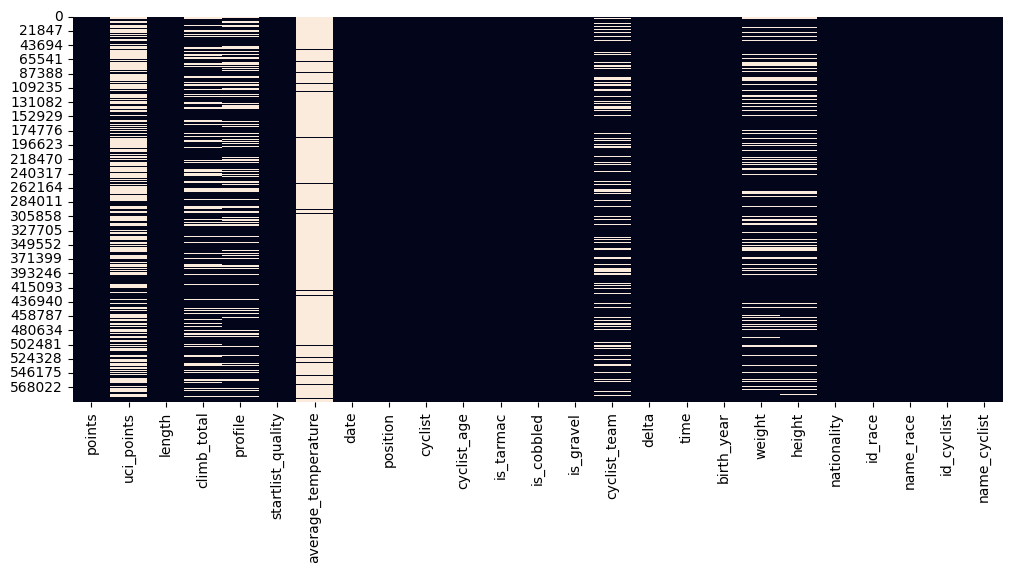

In [16]:
fig, ax = plt.subplots(figsize= (12, 5))
sns.heatmap(df_merged.isnull(), cbar=False, xticklabels=True, ax=ax)

## Data Distribution

Numerical data distribution overview

In [18]:
# for feature in df_merged.select_dtypes(include="number").columns: 
#     sns.displot(df_merged, x=feature, bins=50)

Since we have `delta` and `position` feature, we want to understand if they are consistent. For example, we don't expect to see same `delta` value but with different `position` values.

In [19]:
results = []

for race_url, group in df_merged.groupby('id_race'):  # Replace 'id_race' with the column for race identifier
    duplicate_deltas = (
        group.groupby('delta')
        .filter(lambda x: x['position'].nunique() > 1 and len(x) > 1)
    )
    if not duplicate_deltas.empty:
        duplicate_deltas['race'] = race_url
        results.append(duplicate_deltas)

# Combine all results into a single DataFrame
results_df = pd.concat(results, ignore_index=True)
print(results_df[['race', 'cyclist', 'delta', 'position']])

                                  race           cyclist  delta  position
0         amstel-gold-race/1970/result   georges-pintens    0.0         0
1         amstel-gold-race/1970/result   willy-van-neste    0.0         1
2         amstel-gold-race/1970/result        eric-leman   33.0         3
3         amstel-gold-race/1970/result  joseph-schoeters   33.0         4
4         amstel-gold-race/1970/result    frans-verbeeck   33.0         5
...                                ...               ...    ...       ...
503402  world-championship/2022/result        felix-gall  688.0        96
503403  world-championship/2022/result       stan-dewulf  688.0        97
503404  world-championship/2022/result        daan-hoole  688.0        98
503405  world-championship/2022/result      jake-stewart  905.0       101
503406  world-championship/2022/result      connor-swift  905.0       102

[503407 rows x 4 columns]


Non-numerical data distribution overview

In [20]:
# import signal
# import matplotlib.pyplot as plt

# class TimeoutException(Exception):
#     pass

# def handler(signum, frame):
#     raise TimeoutException()

# signal.signal(signal.SIGALRM, handler)
# TIMEOUT_THRESHOLD = 5

# for feature in df_merged.select_dtypes(exclude="number").columns:
#     try:
#         signal.alarm(TIMEOUT_THRESHOLD)
#         g = sns.displot(df_merged, x=feature,
#                         kind="hist",
#                         row_order="desc",
#                         # bins=df_merged[feature].unique().size,
#                         height=10,
#                         aspect=1.5)
#         plt.xticks(rotation=90, fontsize=10)

#         plt.show()
#         signal.alarm(0)
#     except TimeoutException:
#         print(f"Skipping feature {feature} due to timeout.")
#         continue

# signal.alarm(0)


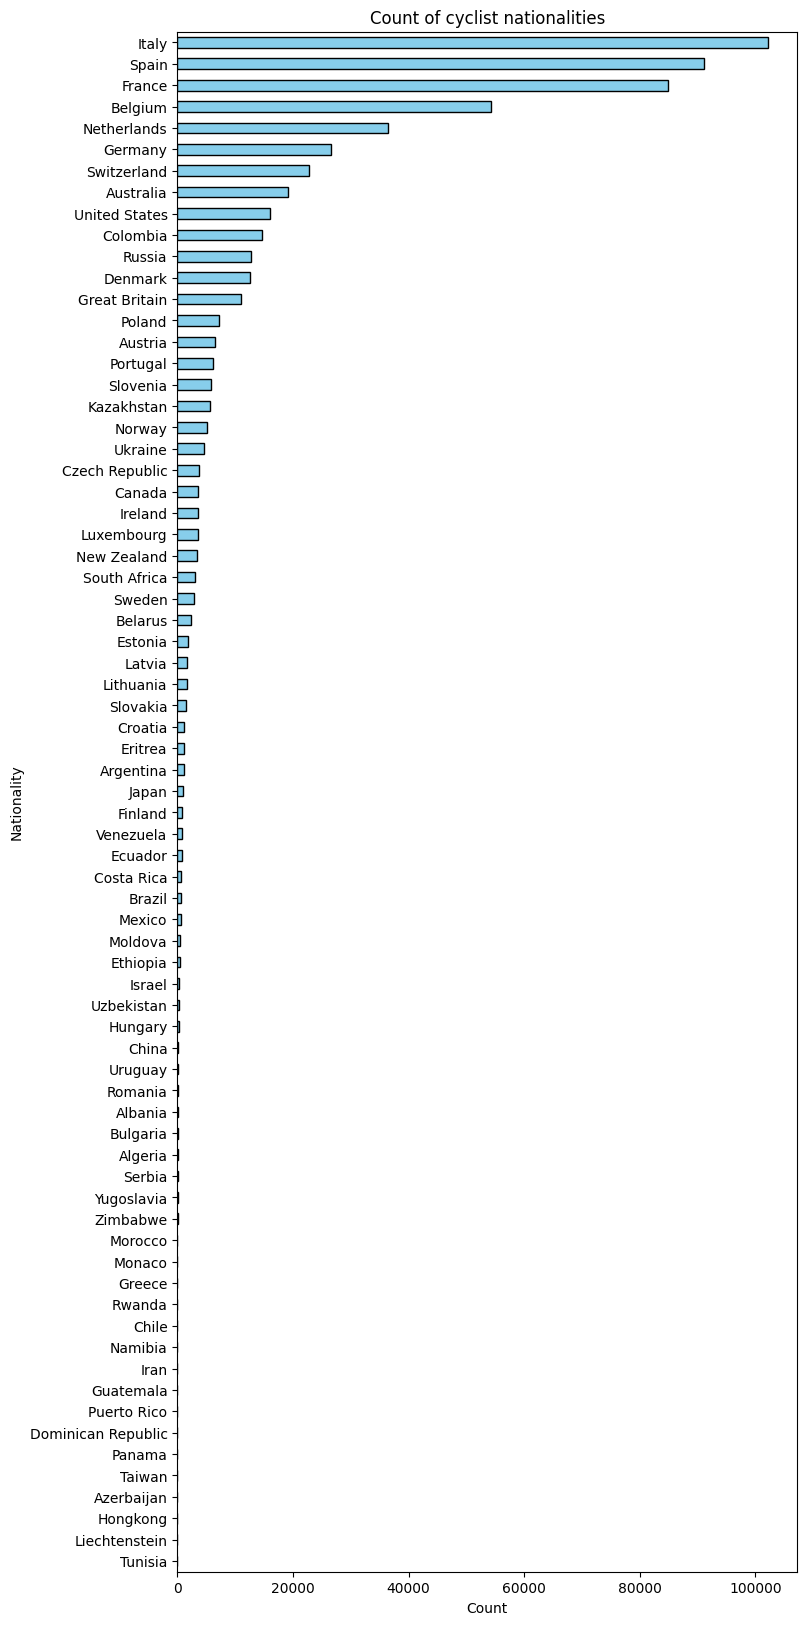

In [21]:
nationality_counts = df_merged['nationality'].value_counts().sort_values()

plt.figure(figsize=(8, 20))
nationality_counts.plot(kind='barh', color='skyblue', edgecolor='black')

plt.title('Count of cyclist nationalities')
plt.xlabel('Count')
plt.ylabel('Nationality')
plt.show()

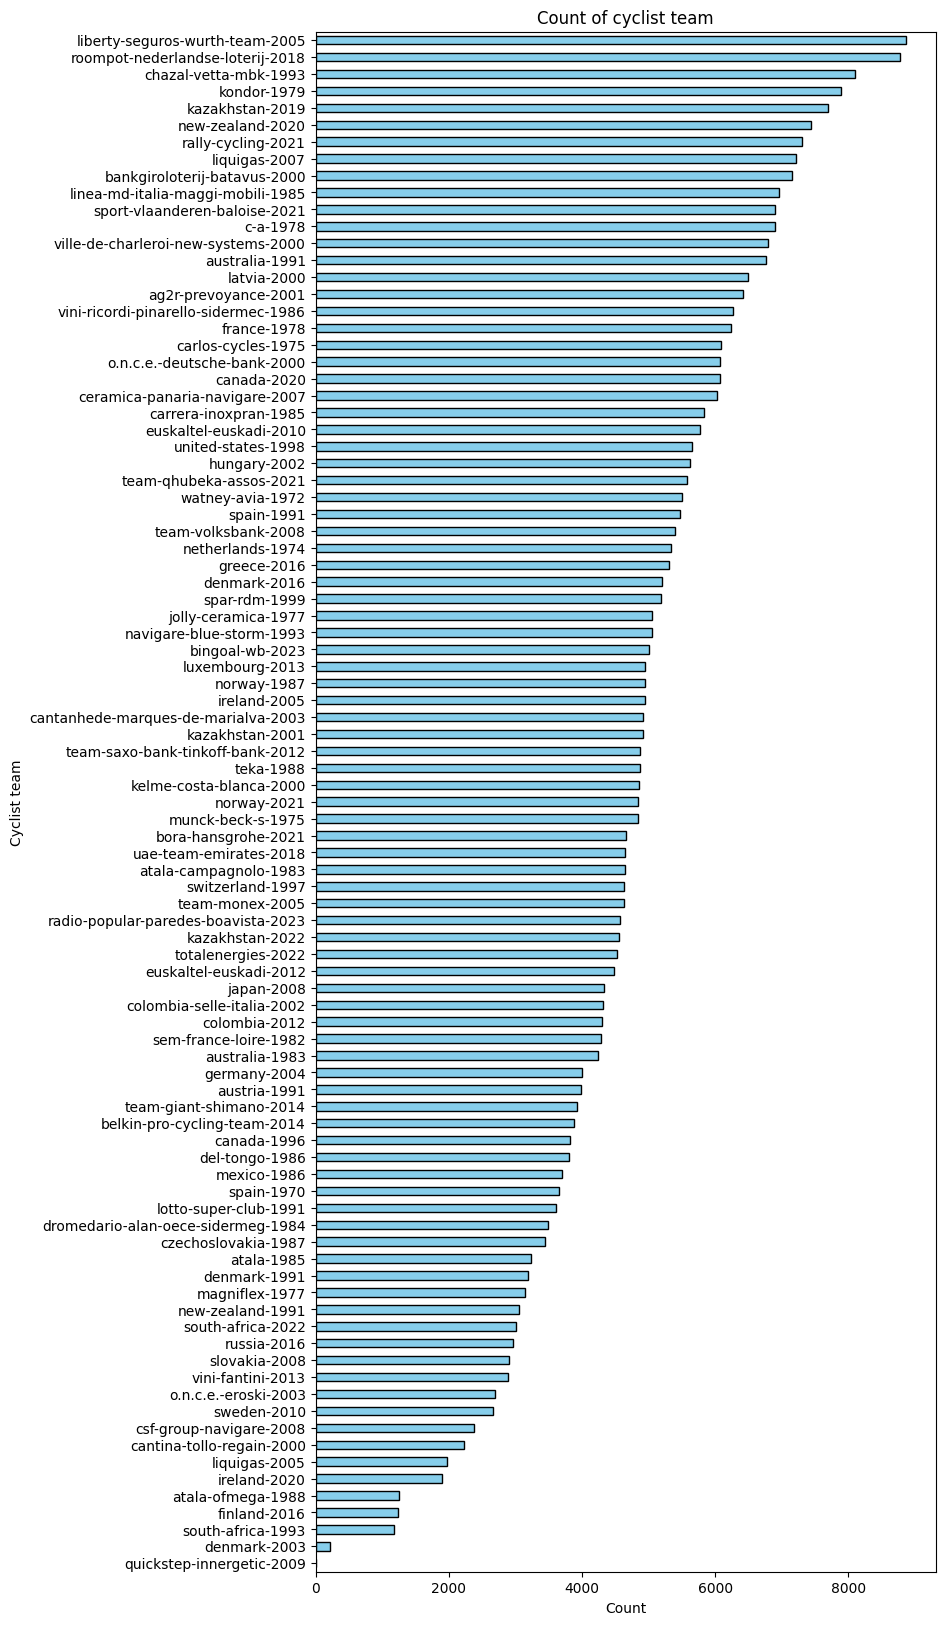

In [22]:
nationality_counts = df_races['cyclist_team'].value_counts().sort_values()

plt.figure(figsize=(8, 20))
nationality_counts.plot(kind='barh', color='skyblue', edgecolor='black')
# display(df_races[df_races['cyclist_team'] == "liberty-seguros-wurth-team-2005"])
plt.title('Count of cyclist team')
plt.xlabel('Count')
plt.ylabel('Cyclist team')
plt.show()

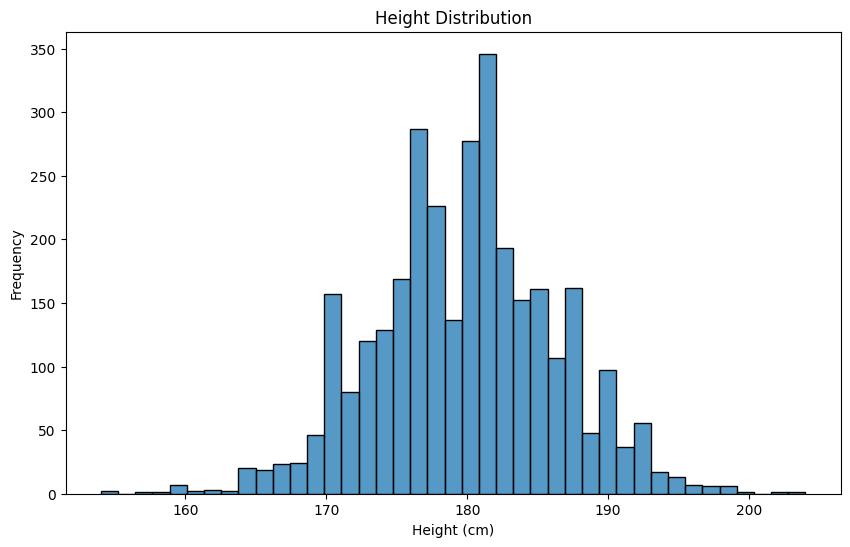

In [23]:
plt.figure(figsize=(10, 6))
sns.histplot(df_cyclists['height'].dropna())
plt.title('Height Distribution')
plt.xlabel('Height (cm)')
plt.ylabel('Frequency')
plt.show()

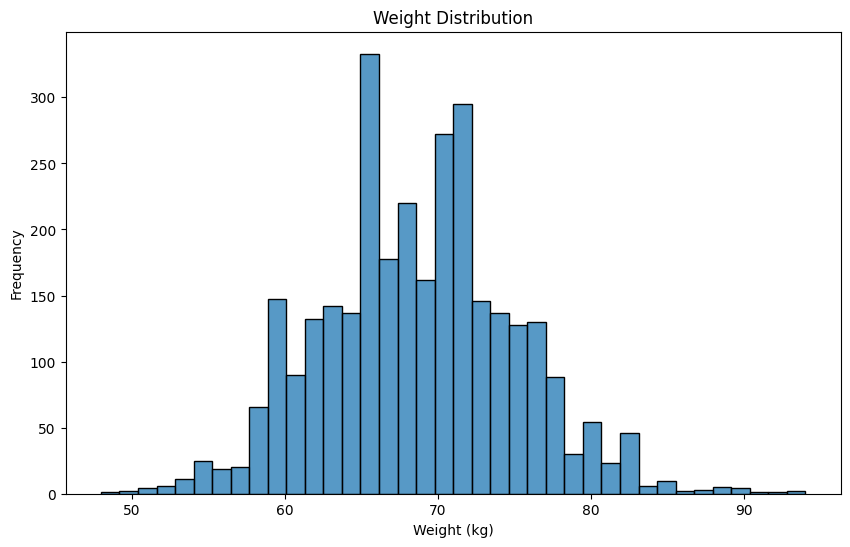

In [25]:
plt.figure(figsize=(10, 6))
sns.histplot(df_cyclists['weight'].dropna())
plt.title('Weight Distribution')
plt.xlabel('Weight (kg)')
plt.ylabel('Frequency')
plt.show()


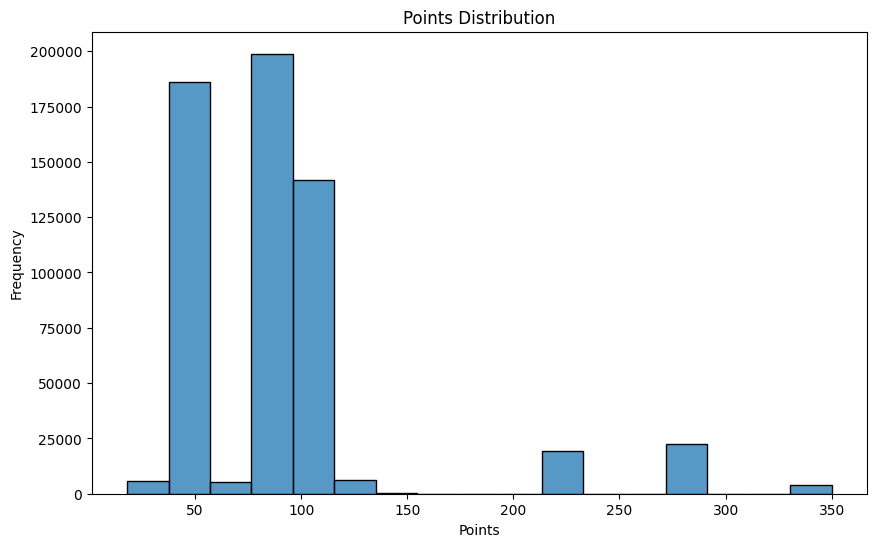

In [26]:
plt.figure(figsize=(10, 6))
sns.histplot(df_races['points'].dropna(), binwidth=20)
plt.title('Points Distribution')
plt.xlabel('Points')
plt.ylabel('Frequency')
plt.show()


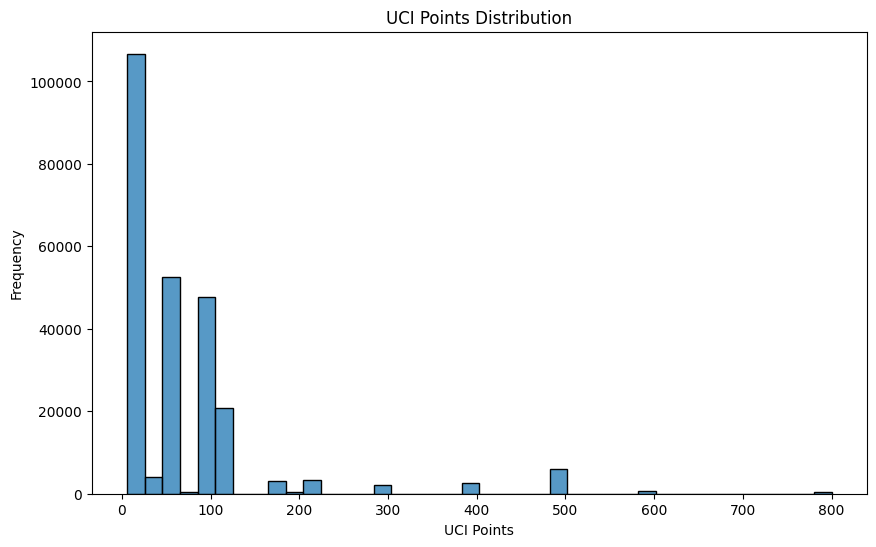

In [27]:
plt.figure(figsize=(10, 6))
sns.histplot(df_races['uci_points'].dropna(), binwidth=20)
plt.title('UCI Points Distribution')
plt.xlabel('UCI Points')
plt.ylabel('Frequency')
plt.show()

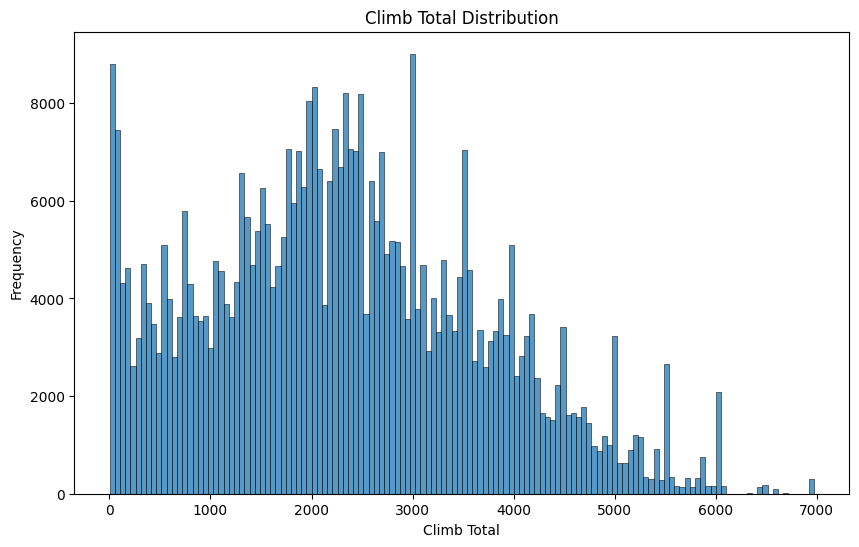

In [28]:
plt.figure(figsize=(10, 6))
sns.histplot(df_races['climb_total'].dropna())
plt.title('Climb Total Distribution')
plt.xlabel('Climb Total')
plt.ylabel('Frequency')
plt.show()

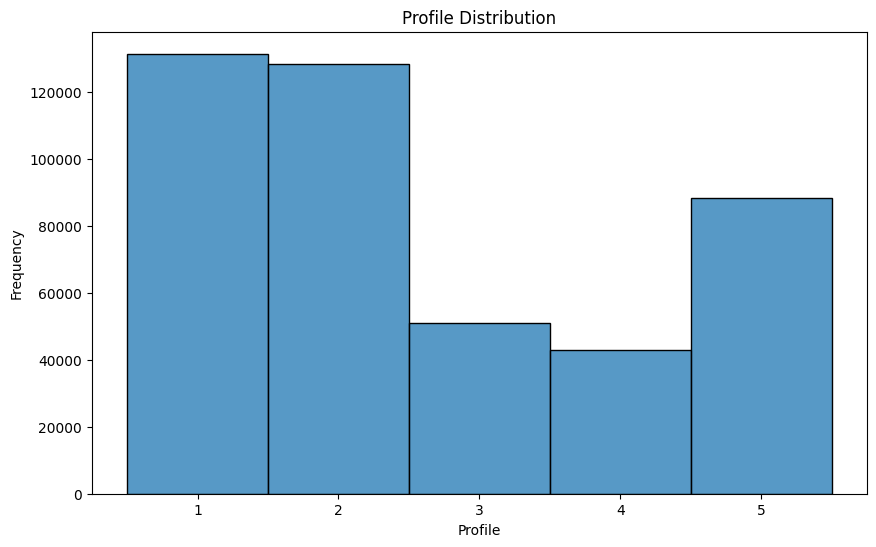

In [29]:
plt.figure(figsize=(10, 6))
sns.histplot(df_races['profile'].dropna())
plt.title('Profile Distribution')
plt.xlabel('Profile')
plt.ylabel('Frequency')
plt.show()

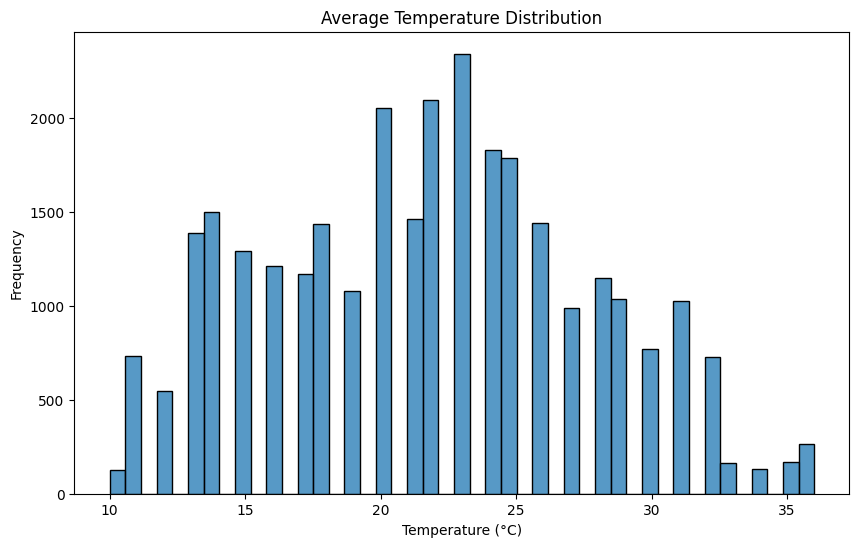

In [30]:
plt.figure(figsize=(10, 6))
sns.histplot(df_races['average_temperature'].dropna())
plt.title('Average Temperature Distribution')
plt.xlabel('Temperature (°C)')
plt.ylabel('Frequency')
plt.show()


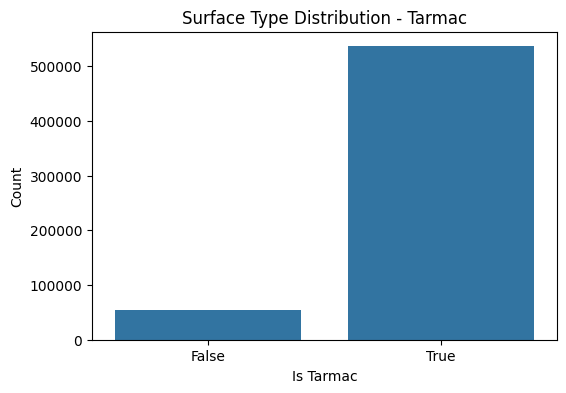

In [31]:
plt.figure(figsize=(6, 4))
sns.countplot(x='is_tarmac', data=df_races)
plt.title('Surface Type Distribution - Tarmac')
plt.xlabel('Is Tarmac')
plt.ylabel('Count')
plt.show()

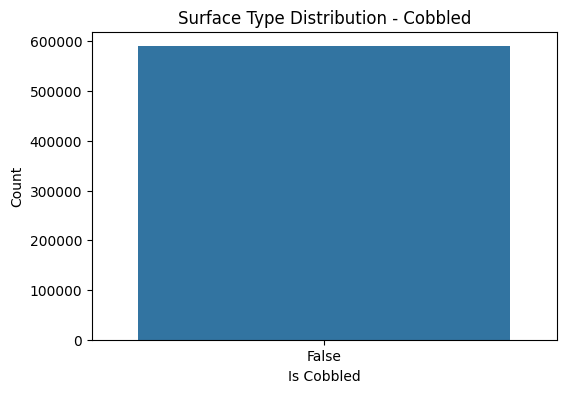

In [32]:
plt.figure(figsize=(6, 4))
sns.countplot(x='is_cobbled', data=df_races)
plt.title('Surface Type Distribution - Cobbled')
plt.xlabel('Is Cobbled')
plt.ylabel('Count')
plt.show()

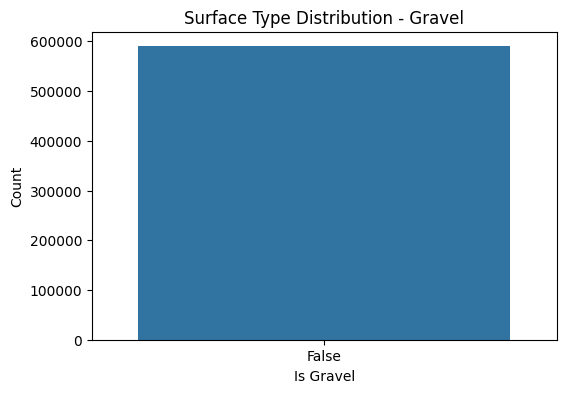

In [33]:
plt.figure(figsize=(6, 4))
sns.countplot(x='is_gravel', data=df_races)
plt.title('Surface Type Distribution - Gravel')
plt.xlabel('Is Gravel')
plt.ylabel('Count')
plt.show()

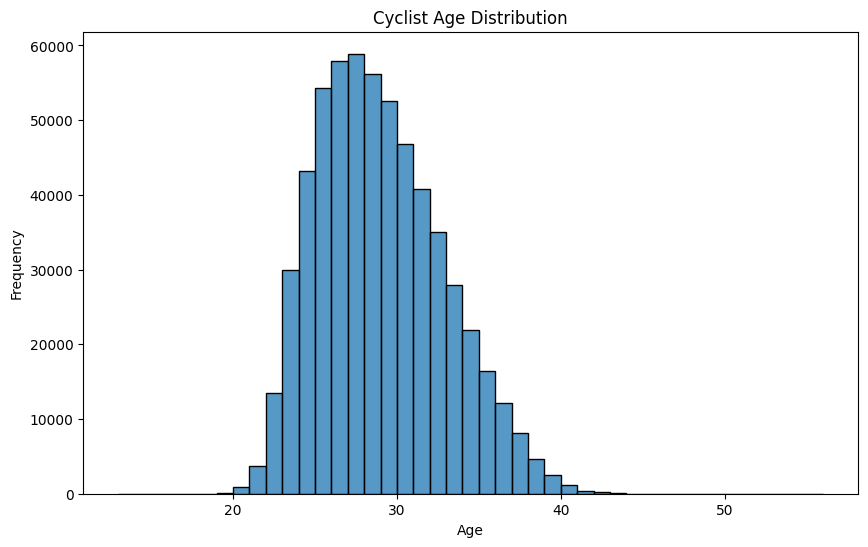

In [34]:
plt.figure(figsize=(10, 6))
sns.histplot(df_races['cyclist_age'].dropna(), binwidth=1)
plt.title('Cyclist Age Distribution')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.show()

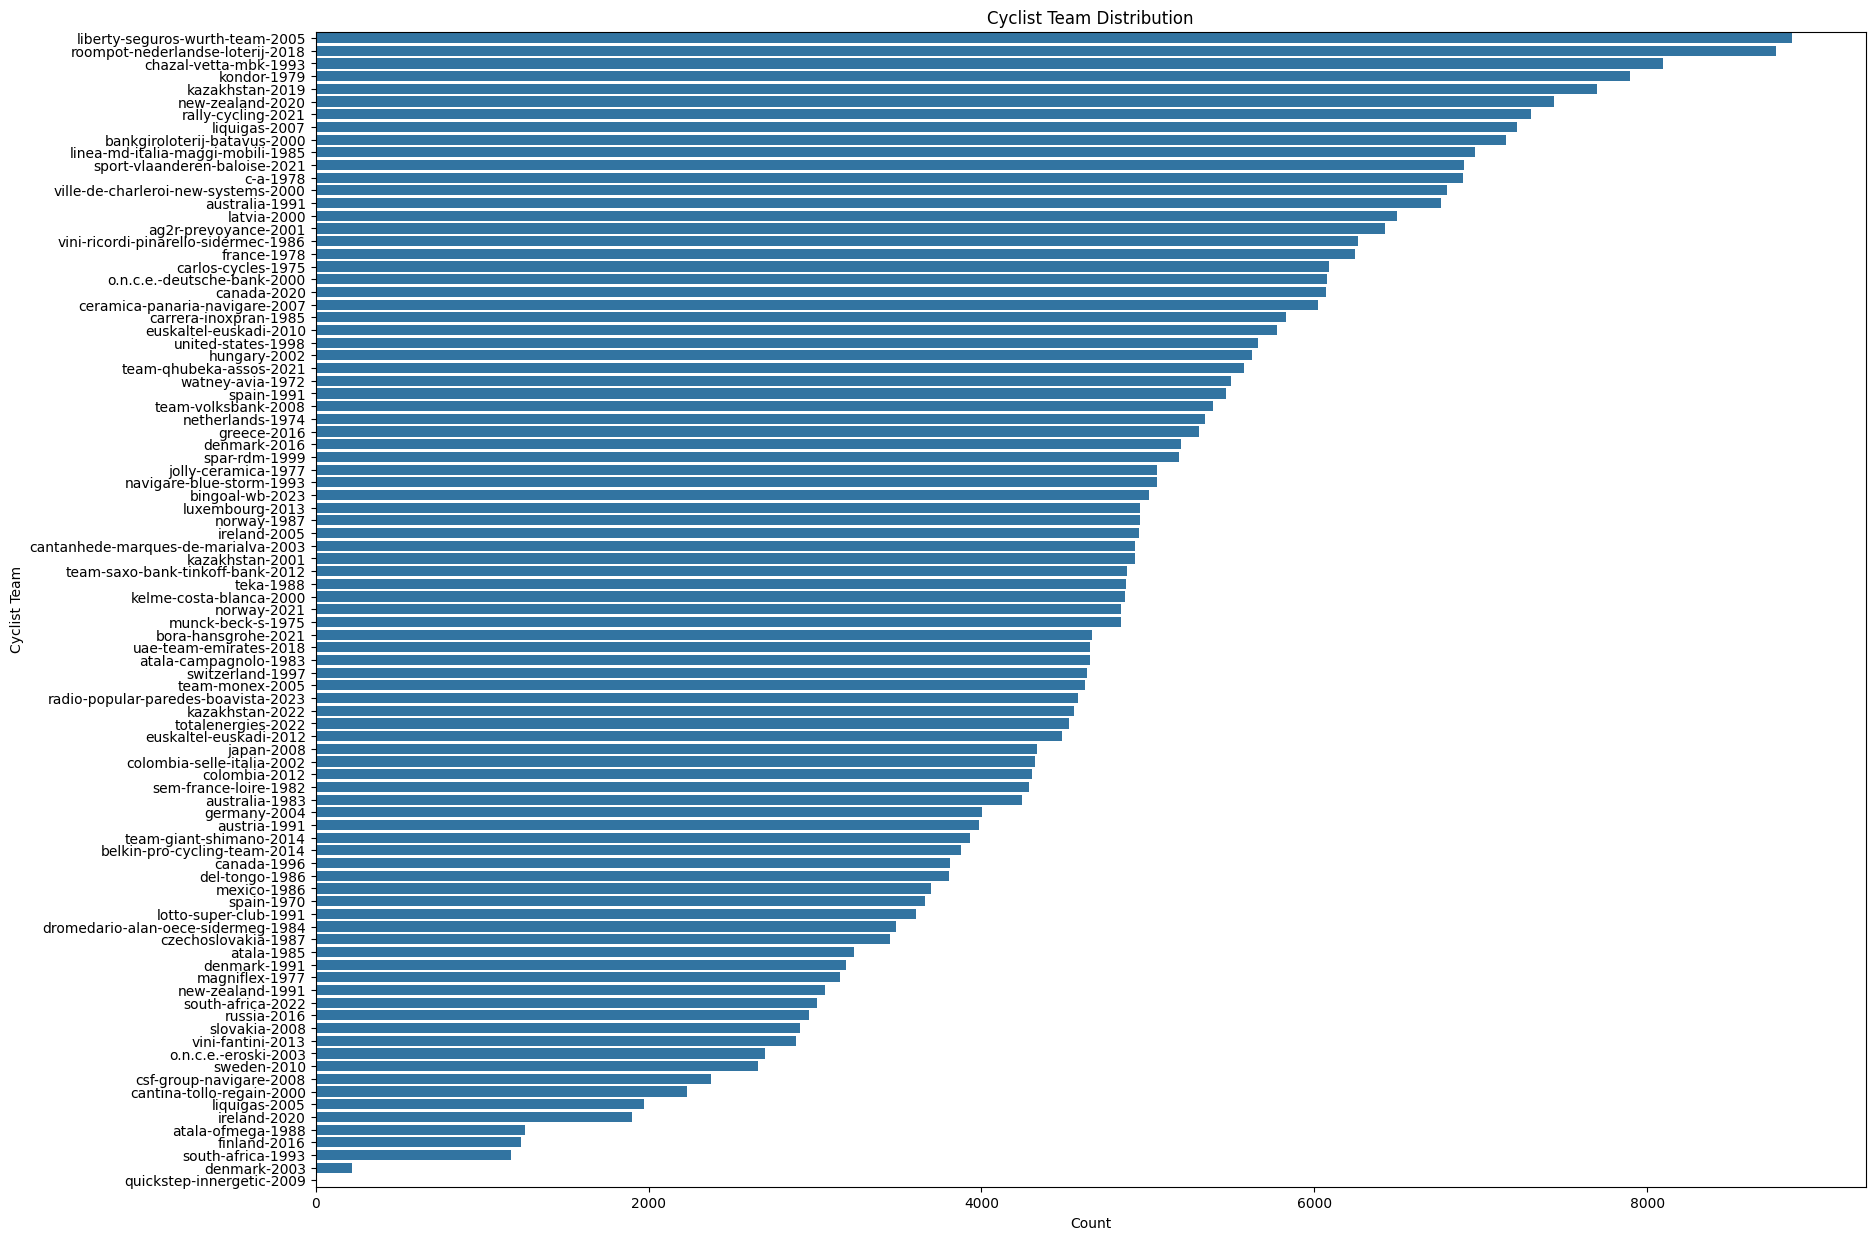

In [35]:
plt.figure(figsize=(20, 15))
sns.countplot(y='cyclist_team', data=df_races, order=df_races['cyclist_team'].value_counts().index)
plt.title('Cyclist Team Distribution')
plt.xlabel('Count')
plt.ylabel('Cyclist Team')
plt.show()

/var/folders/2m/6k44b9f10vv9hpw7fs7d_svm0000gn/T/ipykernel_22471/1844026029.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='date', y='num_cyclists', data=race_counts, palette='viridis')


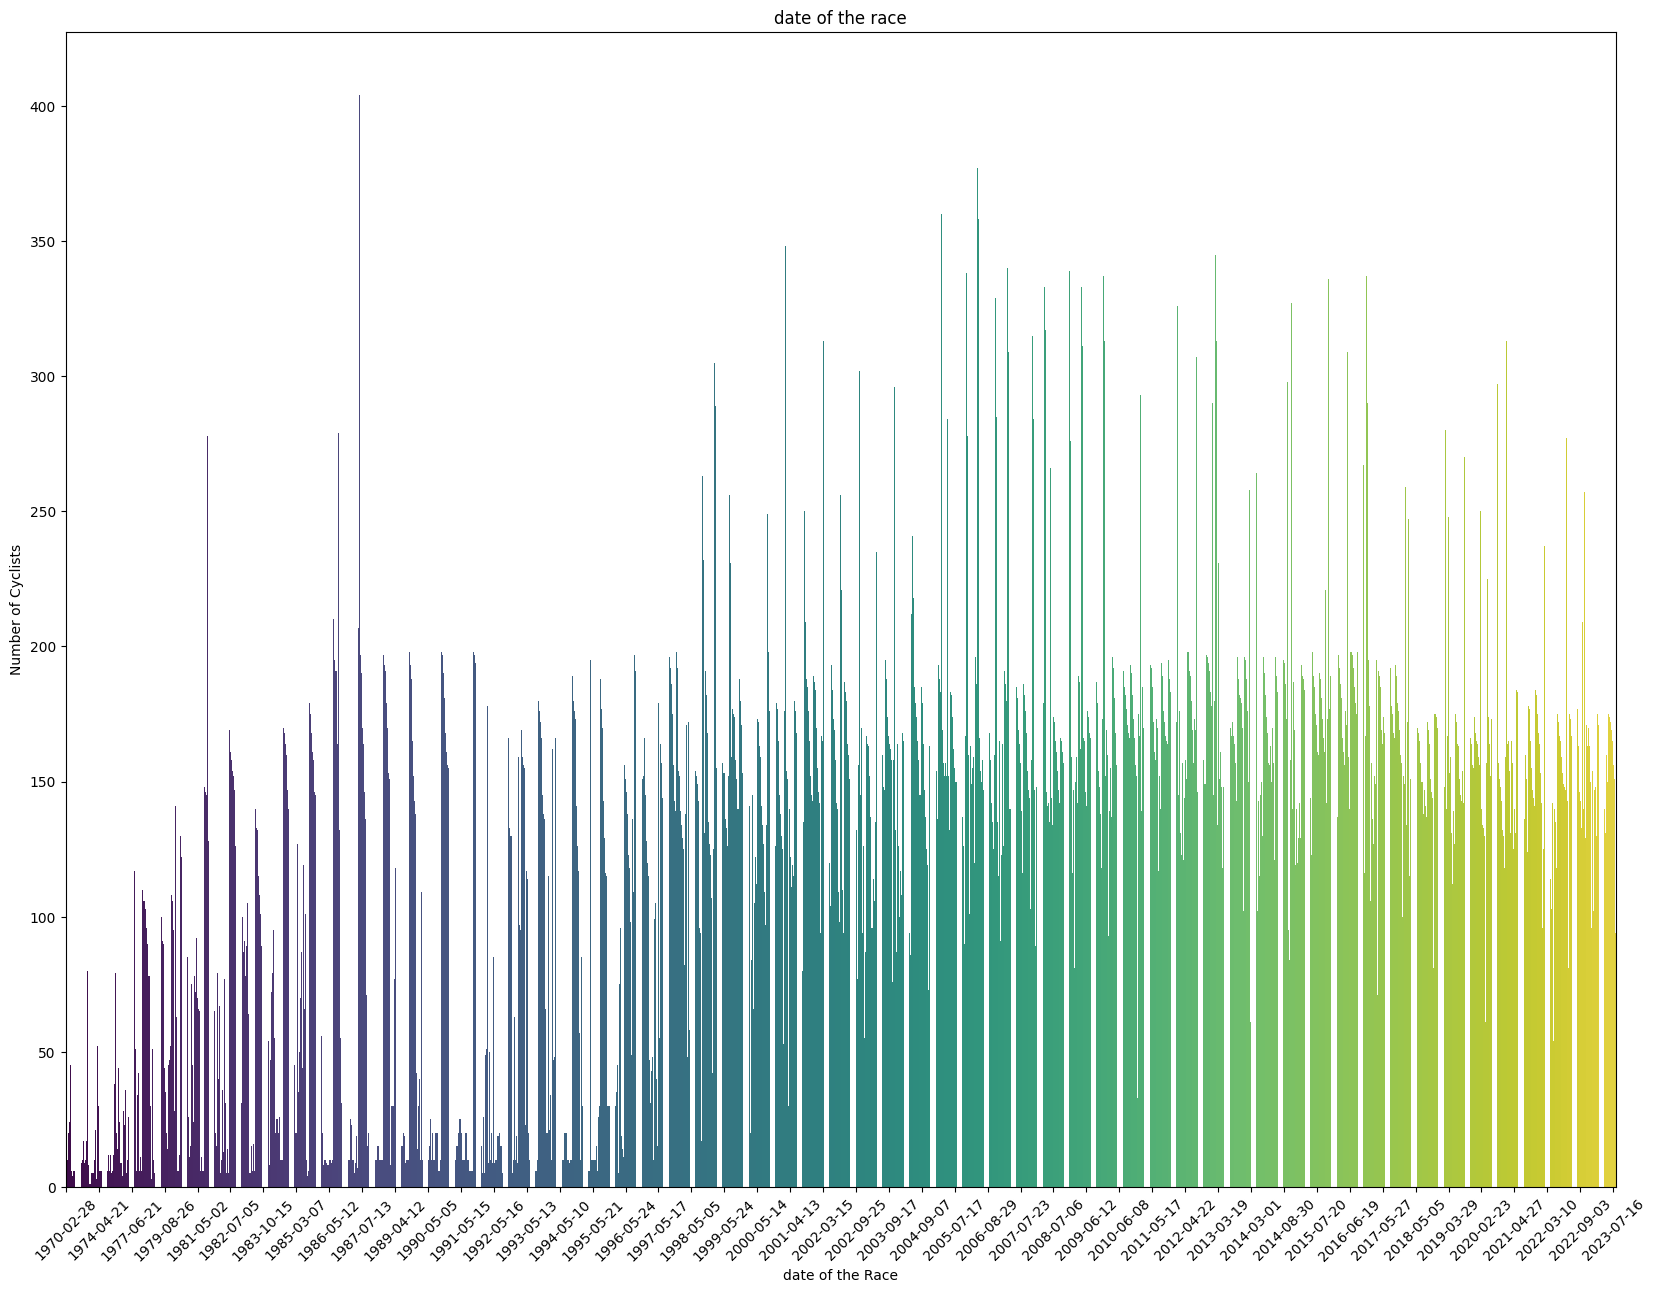

In [36]:
race_counts = df_races.groupby('date').size().reset_index(name='num_cyclists').sort_values(by='date')
plt.figure(figsize=(20, 15))
sns.barplot(x='date', y='num_cyclists', data=race_counts, palette='viridis')
plt.xticks(
    ticks=range(0, len(race_counts), 100),
    labels=race_counts['date'][::100],
    rotation=45
)
plt.xlabel('date of the Race')
plt.ylabel('Number of Cyclists')
plt.title('date of the race')
plt.show()

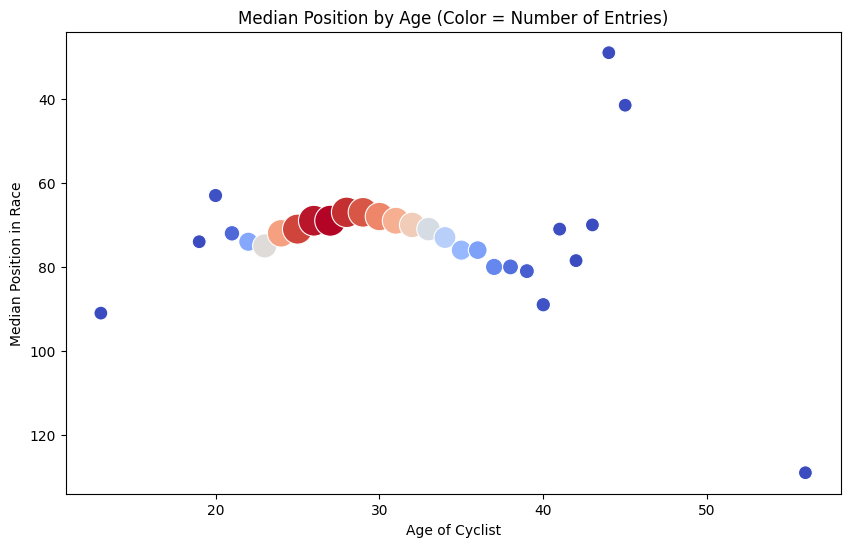

In [37]:
median_positions = df_races.groupby('cyclist_age').agg(
    median_position=('position', 'median'),
    count_entries=('position', 'size')
).reset_index()

plt.figure(figsize=(10, 6))
sns.scatterplot(x='cyclist_age', y='median_position', size='count_entries', data=median_positions, sizes=(100, 500), hue='count_entries', palette='coolwarm', legend=None)

plt.xlabel('Age of Cyclist')
plt.ylabel('Median Position in Race')
plt.title('Median Position by Age (Color = Number of Entries)')
plt.gca().invert_yaxis()

plt.show()

<Axes: xlabel='cyclist_age', ylabel='weight'>

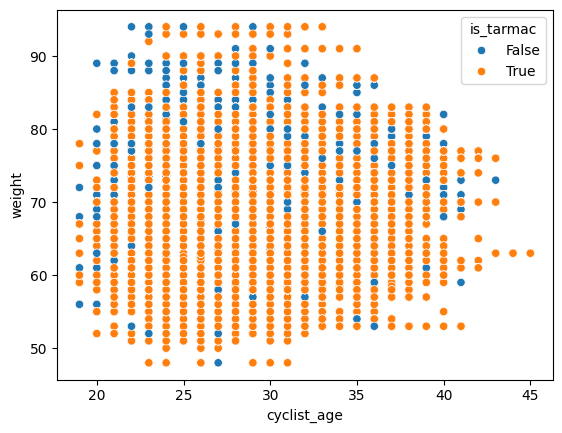

In [38]:
sns.scatterplot(data=df_merged, x="cyclist_age", y="weight", hue="is_tarmac")

<Axes: xlabel='average_temperature', ylabel='points'>

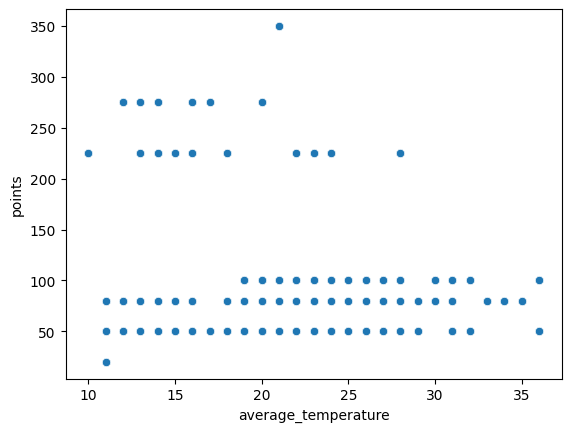

In [39]:
sns.scatterplot(data=df_merged, x="average_temperature", y="points")

<Axes: xlabel='average_temperature', ylabel='uci_points'>

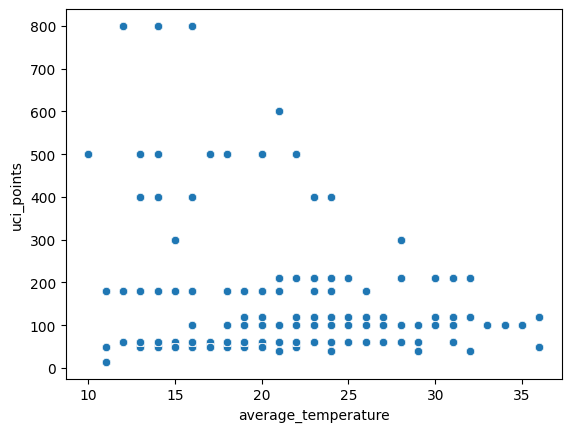

In [40]:
sns.scatterplot(data=df_merged, x="average_temperature", y="uci_points")

<Axes: xlabel='average_temperature', ylabel='climb_total'>

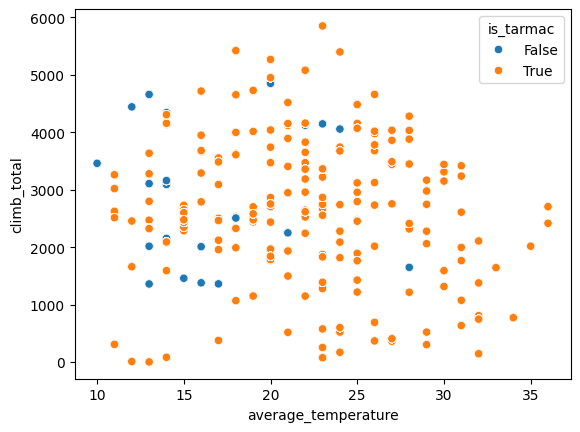

In [41]:
sns.scatterplot(data=df_merged, x="average_temperature", y="climb_total", hue="is_tarmac")

<Axes: xlabel='length', ylabel='climb_total'>

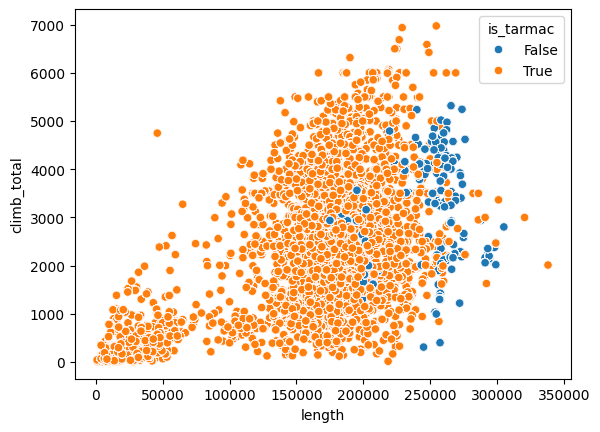

In [42]:
sns.scatterplot(data=df_merged, x="length", y="climb_total", hue="is_tarmac")

<Axes: xlabel='length', ylabel='climb_total'>

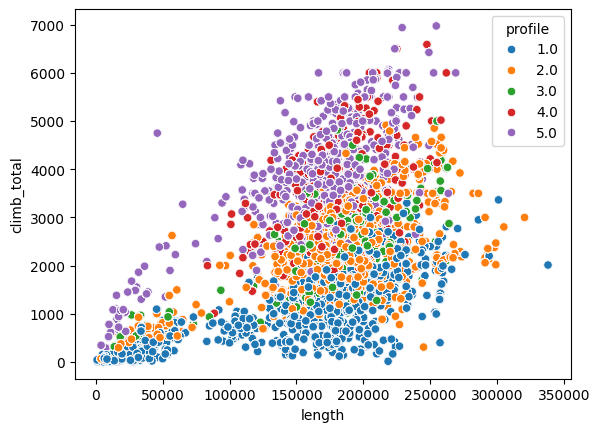

In [43]:
sns.scatterplot(data=df_merged, x="length", y="climb_total", hue="profile")

<Axes: xlabel='points', ylabel='cyclist_age'>

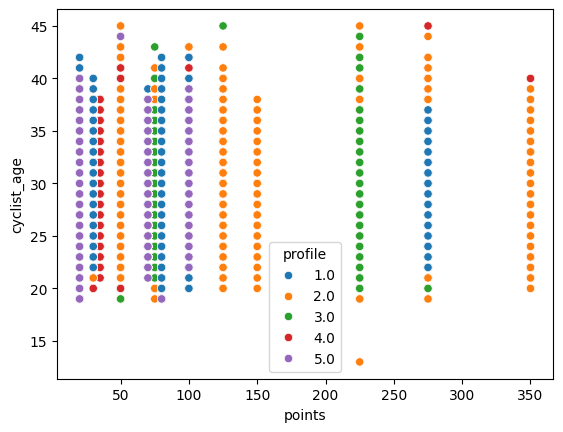

In [44]:
sns.scatterplot(data=df_merged, x="points", y="cyclist_age", hue="profile")

<Axes: xlabel='length', ylabel='points'>

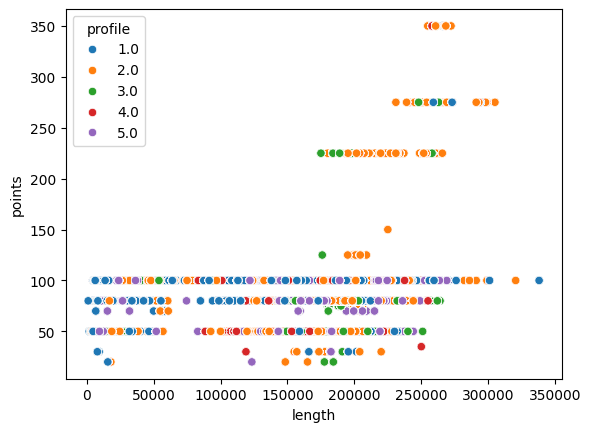

In [45]:
sns.scatterplot(data=df_merged, x="length", y="points", hue="profile")

<Axes: xlabel='length', ylabel='uci_points'>

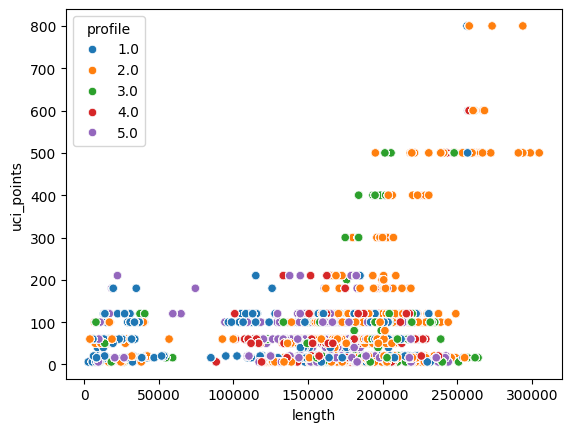

In [46]:
sns.scatterplot(data=df_merged, x="length", y="uci_points", hue="profile")

<Axes: xlabel='length', ylabel='startlist_quality'>

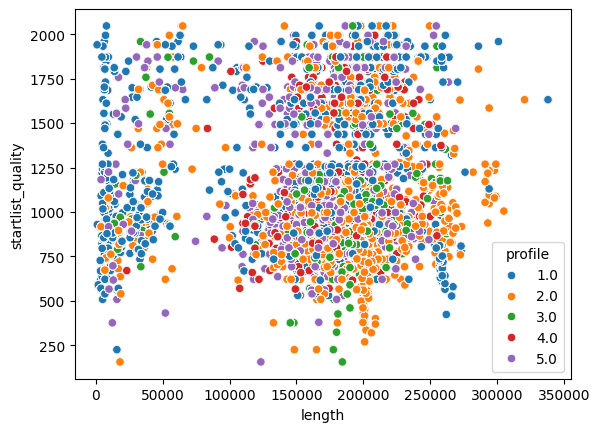

In [47]:
sns.scatterplot(data=df_merged, x="length", y="startlist_quality", hue="profile")

<Axes: xlabel='points', ylabel='startlist_quality'>

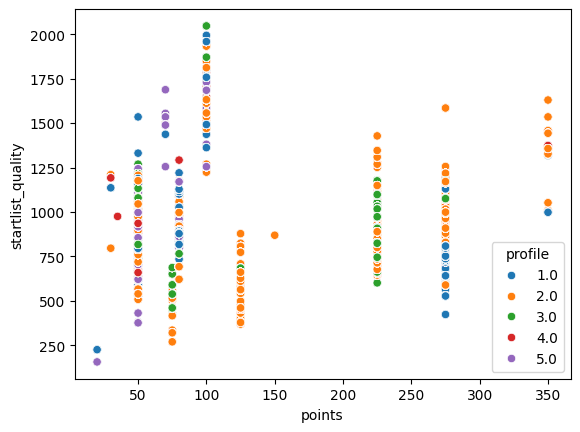

In [48]:
sns.scatterplot(data=df_merged, x="points", y="startlist_quality", hue="profile")

<Axes: xlabel='date', ylabel='startlist_quality'>

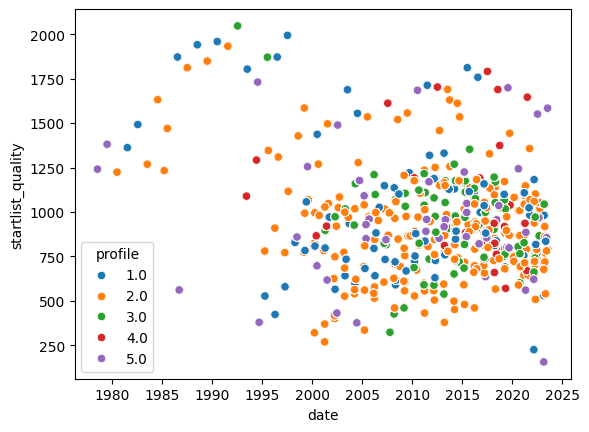

In [49]:
sns.scatterplot(data=df_merged, x="date", y="startlist_quality", hue="profile")

<Axes: xlabel='weight', ylabel='position'>

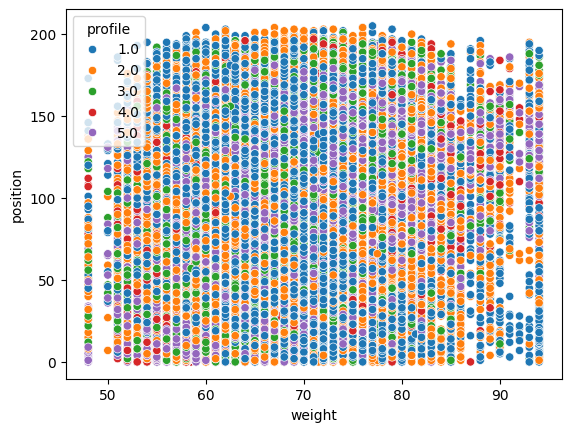

In [50]:
sns.scatterplot(data=df_merged, x="weight", y="position", hue="profile")

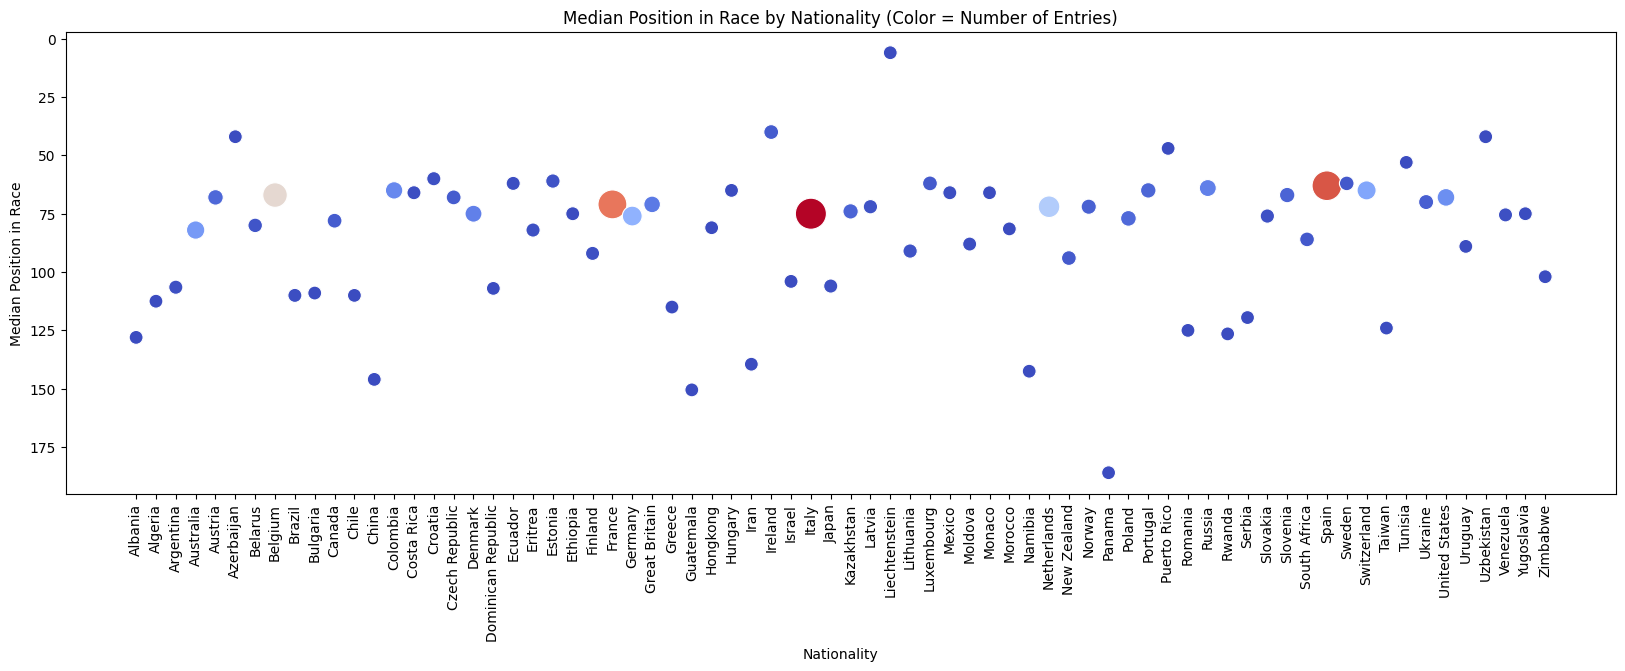

In [51]:
median_positions = df_merged.groupby('nationality').agg(
    median_position=('position', 'median'),
    count_entries=('position', 'size')
).reset_index()

plt.figure(figsize=(20, 6))
sns.scatterplot(x='nationality', y='median_position', size='count_entries', data=median_positions, sizes=(100, 500), hue='count_entries', palette='coolwarm', legend=None)

plt.xticks(rotation=90)
plt.xlabel('Nationality')
plt.ylabel('Median Position in Race')
plt.title('Median Position in Race by Nationality (Color = Number of Entries)')
plt.gca().invert_yaxis()

plt.show()

In [52]:
grouped = df_merged.groupby(['nationality', 'position']).size().reset_index(name='Count')
grouped['total_count'] = grouped.groupby('nationality')['Count'].transform('sum')
grouped['ratio'] = grouped['Count'] / grouped['total_count'] * 1000
sorted_grouped = grouped.sort_values(by=['position', 'ratio'], ascending=[True, False])

print(sorted_grouped)

        nationality  position  Count  total_count      ratio
9124     Uzbekistan         0     21          316  66.455696
7487       Slovakia         0     58         1590  36.477987
4221        Ireland         0     97         3606  26.899612
3846  Great Britain         0    210        11035  19.030358
7674       Slovenia         0     92         5854  15.715750
...             ...       ...    ...          ...        ...
1847       Colombia       207      2        14601   0.136977
1848       Colombia       208      1        14601   0.068488
6331    Netherlands       208      1        36387   0.027482
8655    Switzerland       209      1        22710   0.044033
3645         France       209      1        84926   0.011775

[9506 rows x 5 columns]


,points,uci_points,length,climb_total,startlist_quality,average_temperature,position,cyclist_age,delta,birth_year,weight,height
0,0.198003,NaN,-0.073997,-0.893698,0.36743,NaN,-1.533334,-1.682270,-0.496219,-1.879430,1.395226,0.048132
1,0.198003,NaN,-0.073997,-0.893698,0.36743,NaN,-1.512675,-0.385465,-0.496219,-2.312855,NaN,NaN
2,0.198003,NaN,-0.073997,-0.893698,0.36743,NaN,-1.492015,-1.163548,-0.496219,-2.052800,0.101562,-0.908783
3,0.198003,NaN,-0.073997,-0.893698,0.36743,NaN,-1.471356,0.392619,-0.496219,-2.572911,NaN,NaN
4,0.198003,NaN,-0.073997,-0.893698,0.36743,NaN,-1.450697,-0.385465,-0.496219,-2.312855,-0.868685,-1.227754


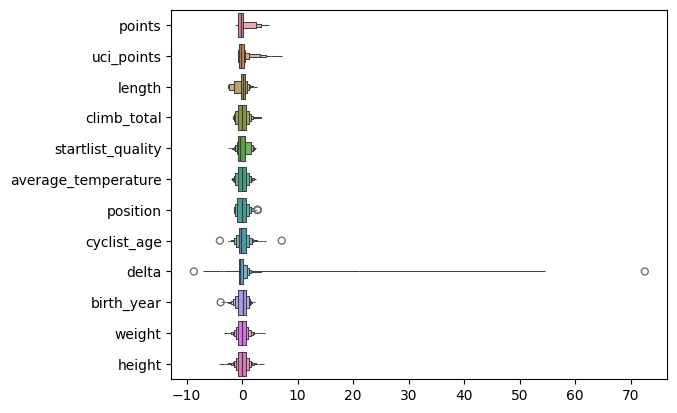

In [54]:
normalized_dataset, normalization_scalers_dataset = center_and_scale(df_merged.select_dtypes(include=np.number))

sns.boxenplot(normalized_dataset, orient="h")
normalized_dataset.head()

In [55]:
normalized_dataset['cyclist'] = df_merged['cyclist']
normalized_dataset['profile'] = df_merged['profile']
normalized_dataset.head()

,points,uci_points,length,climb_total,startlist_quality,average_temperature,position,cyclist_age,delta,birth_year,weight,height,cyclist,profile
0,0.198003,NaN,-0.073997,-0.893698,0.36743,NaN,-1.533334,-1.682270,-0.496219,-1.879430,1.395226,0.048132,sean-kelly,1.0
1,0.198003,NaN,-0.073997,-0.893698,0.36743,NaN,-1.512675,-0.385465,-0.496219,-2.312855,NaN,NaN,gerrie-knetemann,1.0
2,0.198003,NaN,-0.073997,-0.893698,0.36743,NaN,-1.492015,-1.163548,-0.496219,-2.052800,0.101562,-0.908783,rene-bittinger,1.0
3,0.198003,NaN,-0.073997,-0.893698,0.36743,NaN,-1.471356,0.392619,-0.496219,-2.572911,NaN,NaN,joseph-bruyere,1.0
4,0.198003,NaN,-0.073997,-0.893698,0.36743,NaN,-1.450697,-0.385465,-0.496219,-2.312855,-0.868685,-1.227754,sven-ake-nilsson,1.0


/var/folders/2m/6k44b9f10vv9hpw7fs7d_svm0000gn/T/ipykernel_22471/924626047.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped = filtered_df.groupby('profile', group_keys=False)
/var/folders/2m/6k44b9f10vv9hpw7fs7d_svm0000gn/T/ipykernel_22471/924626047.py:8: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  filtered_df = grouped.apply(lambda group: group.sample(n=150, random_state=42))


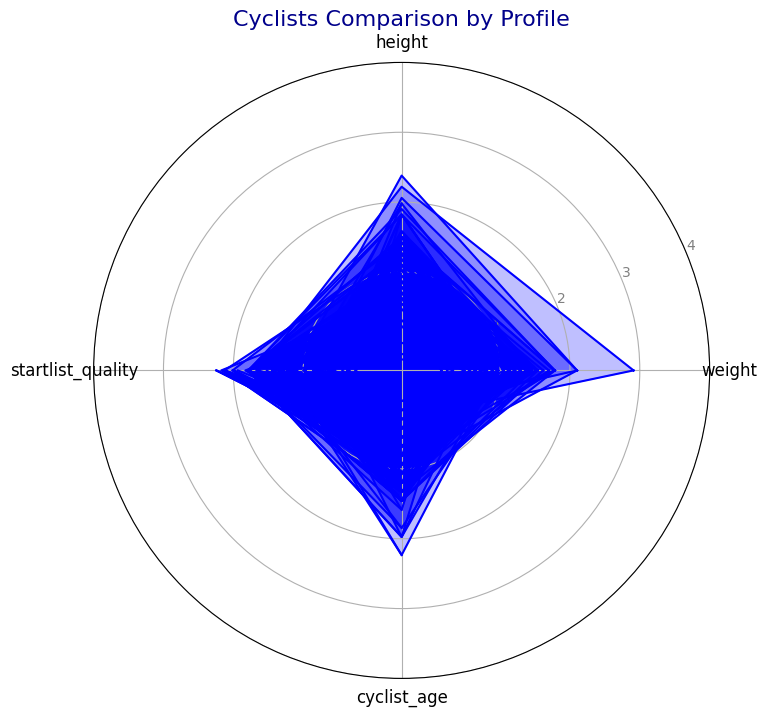

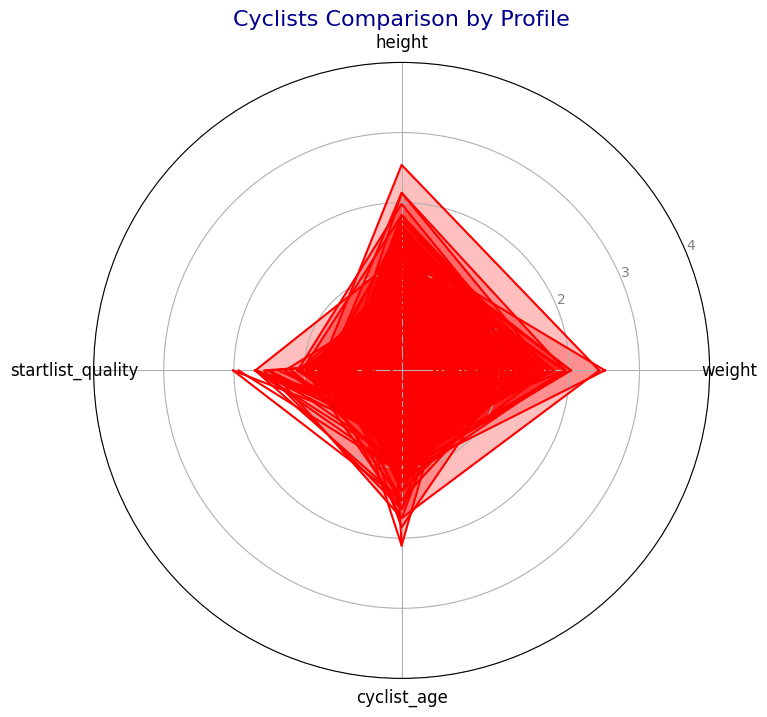

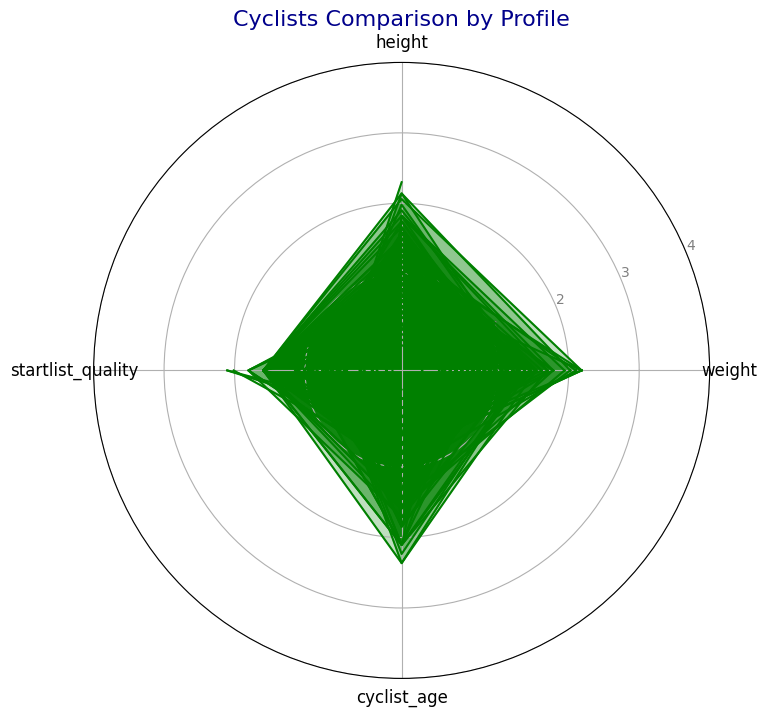

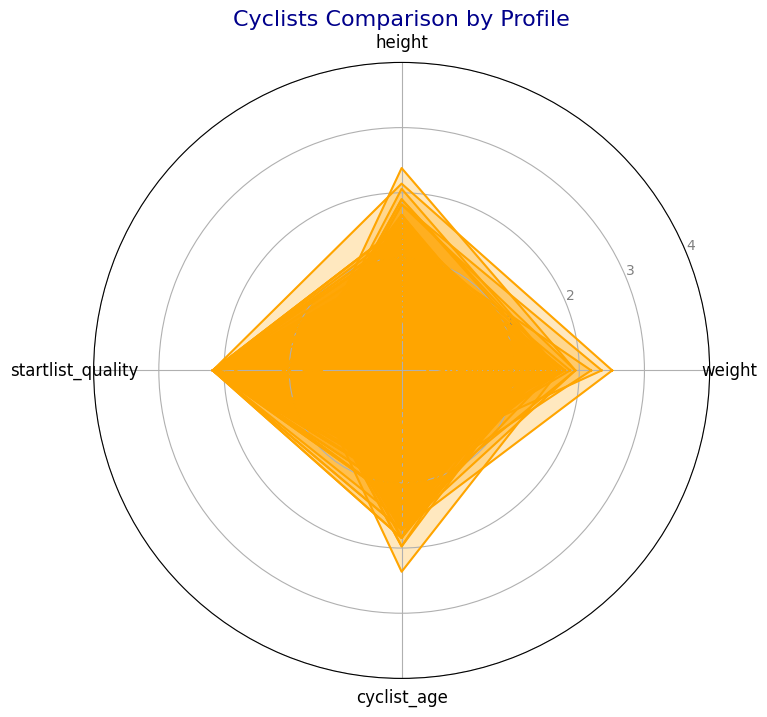

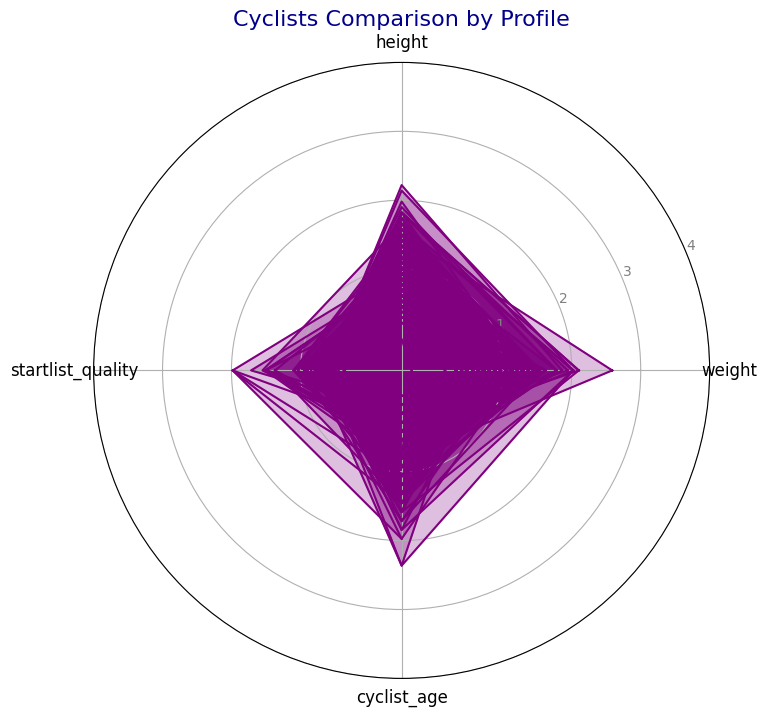

In [56]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

filtered_df = normalized_dataset.drop_duplicates(subset='cyclist')
filtered_df = filtered_df.dropna(subset=['profile'])
grouped = filtered_df.groupby('profile', group_keys=False)
filtered_df = grouped.apply(lambda group: group.sample(n=150, random_state=42))
filtered_df = filtered_df.reset_index(drop=True)

categories = ['weight', 'height', 'startlist_quality', 'cyclist_age']
num_vars = len(categories)

angles = np.linspace(0, 2 * np.pi, num_vars, endpoint=False).tolist()
angles += angles[:1]

profile_colors = {1.: 'blue', 2.: 'red', 3.: 'green', 4.: 'orange', 5.: 'purple'}

for profile_key, profile_value in profile_colors.items():
    df = filtered_df[filtered_df['profile'] == profile_key]


    fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))

    for i, row in df.iterrows():
        values = row[categories].values.flatten().tolist()
        values += values[:1]
        profile = row['profile']
        color = profile_colors.get(profile, 'grey')

        ax.fill(angles, values, color=color, alpha=0.25, label=f"{row['cyclist']} ({profile})")
        ax.plot(angles, values, color=color, linewidth=1.5)

    ax.set_yticks([0, 2, 4, 6])
    ax.set_yticklabels(['1', '2', '3', '4'], color="grey", size=10)
    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(categories, fontsize=12)

    ax.set_title("Cyclists Comparison by Profile", size=16, position=(0.5, 1.1), color="darkblue")
    plt.show()


In [57]:
from typing import Dict
import pandas


def correlations(dataset: pandas.DataFrame) -> pandas.DataFrame:
    correlations_dictionary = {
        correlation_type: dataset.corr(numeric_only=True, method=correlation_type)
        for correlation_type in ("kendall", "pearson", "spearman")
    }
    for i, k in enumerate(correlations_dictionary.keys()):
        correlations_dictionary[k].loc[:, "correlation_type"] = k
    correlations_matrix = pandas.concat(correlations_dictionary.values())

    return correlations_matrix

In [58]:
df_numerical_features = df_merged.dropna().select_dtypes(include=['number'])
normalized_dataset, normalization_scalers_dataset = center_and_scale(df_numerical_features)
correlations = correlations(normalized_dataset)
correlations

,points,uci_points,length,climb_total,startlist_quality,average_temperature,position,cyclist_age,delta,birth_year,weight,height,correlation_type
points,1.000000,0.860994,0.200637,0.044654,0.560150,0.151729,0.016371,0.049198,0.133532,-0.065519,0.085092,0.040916,kendall
uci_points,0.860994,1.000000,0.188210,0.042924,0.534801,0.066974,0.007763,0.043275,0.115837,-0.041739,0.072269,0.035921,kendall
length,0.200637,0.188210,1.000000,0.064639,0.035504,-0.097622,0.000370,0.000076,-0.062641,-0.014964,0.007348,0.002690,kendall
climb_total,0.044654,0.042924,0.064639,1.000000,0.034792,-0.084943,-0.023128,0.004645,0.403906,-0.015898,-0.045566,-0.027229,kendall
startlist_quality,0.560150,0.534801,0.035504,0.034792,1.000000,0.222601,0.054819,0.063040,0.097472,-0.066490,0.081323,0.040652,kendall
average_temperature,0.151729,0.066974,-0.097622,-0.084943,0.222601,1.000000,0.017471,0.025604,0.024801,-0.050242,0.046658,0.024332,kendall
position,0.016371,0.007763,0.000370,-0.023128,0.054819,0.017471,1.000000,0.016919,0.342360,-0.016646,0.157936,0.087734,kendall
cyclist_age,0.049198,0.043275,0.000076,0.004645,0.063040,0.025604,0.016919,1.000000,0.014984,-0.957688,0.053042,-0.023453,kendall
delta,0.133532,0.115837,-0.062641,0.403906,0.097472,0.024801,0.342360,0.014984,1.000000,-0.022803,0.130283,0.066714,kendall
birth_year,-0.065519,-0.041739,-0.014964,-0.015898,-0.066490,-0.050242,-0.016646,-0.957688,-0.022803,1.000000,-0.050489,0.025028,kendall


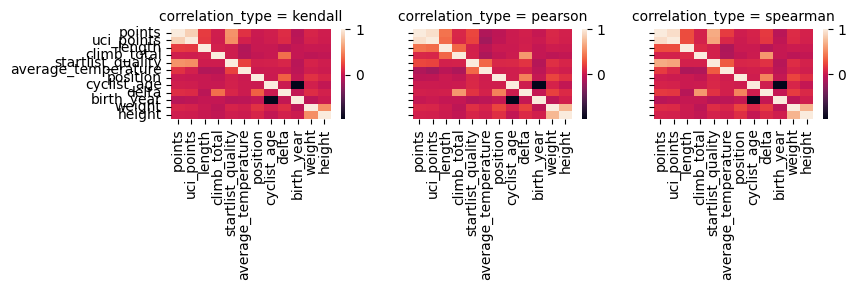

In [59]:
g = sns.FacetGrid(correlations, col="correlation_type")
g.map_dataframe(lambda data, color: sns.heatmap(data[data.columns[:-1]]))

<Axes: >

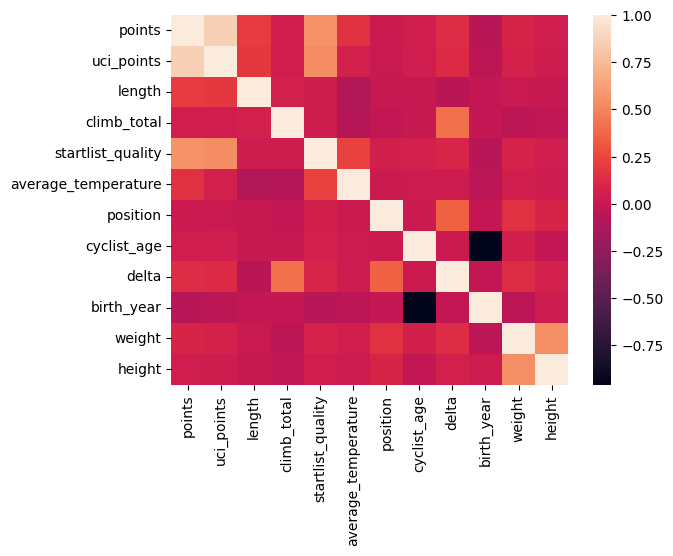

In [60]:
kendall_correlation = correlations.iloc[range(correlations.shape[1]-1), :].drop("correlation_type", axis="columns")
sns.heatmap(kendall_correlation)

In [61]:
df_merged.to_csv('../dataset/merged.csv', index=False)